# 01 - Data Understanding, Cleaning, Missing Values, Preprocessing, ICD-9 Grouping, EDA

## 0. Problem Definition and Unit of Observation
Unit of observation (sample): 1 row = 1 hospital encounter (encounter_id), NOT 1 patient. A patient (patient_nbr) may have multiple hospital encounters → the data should be split by patient_nbr to prevent data leakage (see Section 3).

Problem: Binary classification. The target = 1 if the patient is readmitted within <30 days, and = 0 if the patient is readmitted after >30 days or is not readmitted.

Input: Features related to demographics, treatment processes, diagnoses (diag_1/2/3), and diabetes medications.

Output: target (0/1), with an imbalanced dataset (~11% positive).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

OUTPUT_FIG_DIR = "../outputs/figures"

## 1. Data understanding

In [2]:
df_raw = pd.read_csv("../input/diabetic_data.csv")
ids_mapping = pd.read_csv("../input/IDS_mapping.csv")
print(df_raw.shape)
df_raw.info()
df_raw.describe()
df_raw.describe(include='str')

(101766, 50)
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications   

,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,5346,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,6,3,10,10,18,73,717,749,790,3,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),?,?,?,428,276,250,Norm,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,98569,40256,49949,6862,6752,11555,2597,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


In [3]:
assert df_raw["encounter_id"].is_unique, "encounter_id must be unique"
print("Fully duplicated rows:", df_raw.duplicated().sum())

Fully duplicated rows: 0


In [4]:
#Check the proportion of '?' in each column (before change to NaN)
missing_mark_pct = (df_raw == '?').mean().sort_values(ascending=False)
missing_mark_pct[missing_mark_pct > 0]

weight               0.968585
medical_specialty    0.490822
payer_code           0.395574
race                 0.022336
diag_3               0.013983
diag_2               0.003518
diag_1               0.000206
dtype: float64

In [5]:
df_raw[["max_glu_serum", "A1Cresult"]].isna().mean()

max_glu_serum    0.947468
A1Cresult        0.832773
dtype: float64

**Note.** In the raw file, `max_glu_serum` and `A1Cresult` contain the string "None" (test not performed).
`read_csv` parses it as NaN by default, which explains the high missing rates (94.7% and 83.3%).
Here NaN means *not tested*, not *unknown*, so Section 4.2 fills them with the label "Not tested".

In [6]:
df_raw['readmitted'].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [7]:
# Patient-level statistics
patient_visits = df_raw.groupby("patient_nbr").size()

total_encounters = len(df_raw)
total_patients = df_raw["patient_nbr"].nunique()
repeat_patients = (patient_visits > 1).sum()

print(f"Total encounters: {total_encounters:,}")
print(f"Unique patients: {total_patients:,}")
print(f"Patients with multiple encounters: {repeat_patients:,}")

Total encounters: 101,766
Unique patients: 71,518
Patients with multiple encounters: 16,773


## 2. Cleaning (rule-based) + target creation + ICD-9 grouping

Encounters ending in death or hospice discharge (IDs 11, 13, 14, 19, 20, 21 in `IDS_mapping.csv`)
are removed: these patients cannot be readmitted, so keeping them would bias the target downward.
The "unknown" admission/discharge codes (IDs 18/25/26, 9/15/17/20/21, 5/6/8) are merged into one label "Unknown".

In [8]:
# Rule-based: fixed values, no statistics learned from data -> safe before split
EXPIRED_HOSPICE_IDS = [11, 13, 14, 19, 20, 21]  # from IDS_mapping.csv (Expired / Hospice)

df_step1 = df_raw.replace("?", np.nan)
n_before = df_step1.shape[0]
df_step1 = df_step1[~df_step1["discharge_disposition_id"].isin(EXPIRED_HOSPICE_IDS)].copy()
print(f"Removed {n_before - df_step1.shape[0]} rows (expired/hospice). "
      f"{df_step1.shape[0]} rows remaining.")

Removed 2423 rows (expired/hospice). 99343 rows remaining.


In [9]:
#create target
df_step1["target"] = (df_step1["readmitted"] == "<30").astype(int)
df_step1 = df_step1.drop(columns=["readmitted"])

In [10]:
#merge unknown/not available
UNKNOWN_CODES = {
    "discharge_disposition_id": [18, 25, 26],
    "admission_source_id": [9, 15, 17, 20, 21],
    "admission_type_id": [5, 6, 8],
}
for col, codes in UNKNOWN_CODES.items():
    df_step1[col] = df_step1[col].where(~df_step1[col].isin(codes), "Unknown")

In [11]:
def map_icd9(code):
    if pd.isna(code):
        return "Missing"
    code = str(code).strip()
    if not code:
        return "Missing"
    if code.startswith("V"):
        return "Supplementary_V"
    if code.startswith("E"):
        return "External_cause_E"
    try:
        c = int(float(code))
    except ValueError:
        return "Other"

    if 250 <= c < 251:
        return "Diabetes"
    if 390 <= c <= 459 or c == 785:
        return "Circulatory"
    if 460 <= c <= 519 or c == 786:
        return "Respiratory"
    if 520 <= c <= 579 or c == 787:
        return "Digestive"
    if 800 <= c <= 999:
        return "Injury"
    if 710 <= c <= 739:
        return "Musculoskeletal"
    if 580 <= c <= 629 or c == 788:
        return "Genitourinary"
    if 140 <= c <= 239:
        return "Neoplasms"
    if 1 <= c <= 139:
        return "Infectious"
    if 240 <= c <= 279:
        return "Endocrine_other"
    if 280 <= c <= 289:
        return "Blood"
    if 290 <= c <= 319:
        return "Mental"
    if 320 <= c <= 389:
        return "Nervous_SenseOrgans"
    if 630 <= c <= 679:
        return "Pregnancy_Childbirth"
    if 680 <= c <= 709:
        return "Skin"
    if 740 <= c <= 759:
        return "Congenital"
    if 760 <= c <= 779:
        return "Perinatal"
    if 780 <= c <= 799:
        return "Symptoms_signs"
    return "Other"

for col in ["diag_1", "diag_2", "diag_3"]:
    df_step1[f"{col}_group"] = df_step1[col].apply(map_icd9)

df_step1.shape

(99343, 53)

## 3. Split train/test set by patient_nbr

In [12]:
splitter = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42)
train_idx, test_idx = next(splitter.split(df_step1, groups=df_step1["patient_nbr"]))
train_df = df_step1.iloc[train_idx].reset_index(drop=True)
test_df = df_step1.iloc[test_idx].reset_index(drop=True)
print(f"Train: {train_df.shape[0]} rows / Test: {test_df.shape[0]} rows")

Train: 79541 rows / Test: 19802 rows


The split is grouped by `patient_nbr` (no patient appears in both sets) but not stratified;
the positive rate is similar in train and test (11.4% vs 11.2%, see Section 5).

In [13]:
from scipy.stats import chi2_contingency

for col in ["medical_specialty", "payer_code", "race"]:
    ct = pd.crosstab(train_df[col].isna(), train_df["target"])
    chi2, p, dof, exp = chi2_contingency(ct)
    conclusion = "Associated with target" if p < 0.05 else "No clear association found"
    print(f"{col}: missing rate = {train_df[col].isna().mean():.2%}, "
        f"chi-square p-value = {p:.4g} ({conclusion})")

medical_specialty: missing rate = 48.92%, chi-square p-value = 1.981e-05 (Associated with target)
payer_code: missing rate = 39.68%, chi-square p-value = 0.0738 (No clear association found)
race: missing rate = 2.28%, chi-square p-value = 1.976e-05 (Associated with target)


## 4. Steps Fitted on Train and Applied to Test

### 4.1. Drop Near-Constant Medication Columns (Fitted on Train)

In [14]:
MED_COLS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
]
NEAR_CONSTANT_THRESHOLD = 0.99

# Decide on TRAIN only
top_freq = pd.Series({
    c: train_df[c].value_counts(normalize=True, dropna=False).iloc[0]
    for c in MED_COLS
}).sort_values(ascending=False)
print(top_freq.round(4))

dropped_cols = top_freq[top_freq >= NEAR_CONSTANT_THRESHOLD].index.tolist()
print("Columns to drop (fitted on train):", dropped_cols)

# Apply to both
train_df = train_df.drop(columns=dropped_cols)
test_df = test_df.drop(columns=dropped_cols)
train_df.shape, test_df.shape

examide                     1.0000
glimepiride-pioglitazone    1.0000
citoglipton                 1.0000
metformin-pioglitazone      1.0000
acetohexamide               1.0000
metformin-rosiglitazone     1.0000
troglitazone                1.0000
glipizide-metformin         0.9998
tolbutamide                 0.9998
miglitol                    0.9997
tolazamide                  0.9996
chlorpropamide              0.9992
acarbose                    0.9968
glyburide-metformin         0.9932
nateglinide                 0.9931
repaglinide                 0.9844
glimepiride                 0.9480
rosiglitazone               0.9362
pioglitazone                0.9271
glyburide                   0.8946
glipizide                   0.8742
metformin                   0.7990
insulin                     0.4655
dtype: float64
Columns to drop (fitted on train): ['examide', 'glimepiride-pioglitazone', 'citoglipton', 'metformin-pioglitazone', 'acetohexamide', 'metformin-rosiglitazone', 'troglitazone', 'gli

((79541, 38), (19802, 38))

### 4.2 Missing values

In [15]:
# Fixed labels, not learned from data -> same rule for train and test
train_df = train_df.drop(columns=["weight"])
test_df = test_df.drop(columns=["weight"])

for col in ["payer_code", "medical_specialty", "race"]:
    train_df[col] = train_df[col].fillna("Unknown")
    test_df[col] = test_df[col].fillna("Unknown")

for col in ["max_glu_serum", "A1Cresult"]:
    train_df[col] = train_df[col].fillna("Not tested")
    test_df[col] = test_df[col].fillna("Not tested")

na_left = train_df.isna().sum()
print("Remaining NaN in train:\n", na_left[na_left > 0])

Remaining NaN in train:
 diag_1      15
diag_2     296
diag_3    1169
dtype: int64


### 4.3 Categorical Data Types (Categories Fitted on Train)

In [16]:
MED_KEPT = [c for c in MED_COLS if c not in dropped_cols]

CATEGORICAL_COLS = [
    "race", "gender", "age", "admission_type_id", "discharge_disposition_id",
    "admission_source_id", "payer_code", "medical_specialty",
    "max_glu_serum", "A1Cresult", "change", "diabetesMed",
    "diag_1_group", "diag_2_group", "diag_3_group",
] + MED_KEPT

UNSEEN_LABEL = "Other_unseen"

# Category sets learned from TRAIN only
categories = {
    col: sorted(train_df[col].dropna().astype(str).unique().tolist())
    for col in CATEGORICAL_COLS
}

# Apply to both; values unseen in train -> "Other_unseen"
for df in (train_df, test_df):
    for col, cats in categories.items():
        vals = df[col].astype(str)
        vals = vals.where(vals.isin(cats), UNSEEN_LABEL)
        df[col] = pd.Categorical(vals, categories=cats + [UNSEEN_LABEL])

train_df.dtypes

encounter_id                   int64
patient_nbr                    int64
race                        category
gender                      category
age                         category
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
time_in_hospital               int64
payer_code                  category
medical_specialty           category
num_lab_procedures             int64
num_procedures                 int64
num_medications                int64
number_outpatient              int64
number_emergency               int64
number_inpatient               int64
diag_1                           str
diag_2                           str
diag_3                           str
number_diagnoses               int64
max_glu_serum               category
A1Cresult                   category
metformin                   category
repaglinide                 category
glimepiride                 category
glipizide                   category
g

### 4.4 Outlier Treatment (Fitted on Train)

In [17]:
OUTLIER_COLS = ["num_medications", "num_lab_procedures",
                "number_inpatient", "number_emergency", "number_outpatient"]

# Thresholds from TRAIN only (winsorize at 1st / 99th percentile)
outlier_caps = {}
for col in OUTLIER_COLS:
    lo, hi = train_df[col].quantile((0.01, 0.99), interpolation="nearest")
    outlier_caps[col] = (int(lo), int(hi))
print("Capping thresholds (fitted on train):", outlier_caps)

# Save data before clipping
before = train_df[OUTLIER_COLS].copy()

# Apply to both
for col, (lo, hi) in outlier_caps.items():
    for name, df in (("train", train_df), ("test", test_df)):
        print(f"{col} [{name}]: {(df[col] < lo).sum()} below {lo}, {(df[col] > hi).sum()} above {hi}")
        df[col] = df[col].clip(lower=lo, upper=hi)

Capping thresholds (fitted on train): {'num_medications': (3, 43), 'num_lab_procedures': (1, 84), 'number_inpatient': (0, 6), 'number_emergency': (0, 3), 'number_outpatient': (0, 5)}
num_medications [train]: 584 below 3, 757 above 43
num_medications [test]: 133 below 3, 171 above 43
num_lab_procedures [train]: 0 below 1, 741 above 84
num_lab_procedures [test]: 0 below 1, 208 above 84
number_inpatient [train]: 0 below 0, 534 above 6
number_inpatient [test]: 0 below 0, 170 above 6
number_emergency [train]: 0 below 0, 726 above 3
number_emergency [test]: 0 below 0, 204 above 3
number_outpatient [train]: 0 below 0, 721 above 5
number_outpatient [test]: 0 below 0, 182 above 5


## 5. Post-Split Checks (Target Balance and No Patient Overlap)

In [18]:
print('Target - train rate:', train_df['target'].mean())
print('Target - test rate:', test_df['target'].mean())
overlap_patients = set(train_df['patient_nbr']) & set(test_df['patient_nbr'])
print('Number of patients overlapping between train/test (should be 0):', len(overlap_patients))

Target - train rate: 0.11438126249355678
Target - test rate: 0.11190788809211191
Number of patients overlapping between train/test (should be 0): 0


In [19]:
# Save patient groups for group-aware cross-validation
train_df[["patient_nbr"]].to_csv(
    "../data/train_patient_groups.csv",
    index=False
)

test_df[["patient_nbr"]].to_csv(
    "../data/test_patient_groups.csv",
    index=False
)

train_df = train_df.drop(columns=["patient_nbr", "encounter_id"])
test_df = test_df.drop(columns=["patient_nbr", "encounter_id"])

## 6. EDA

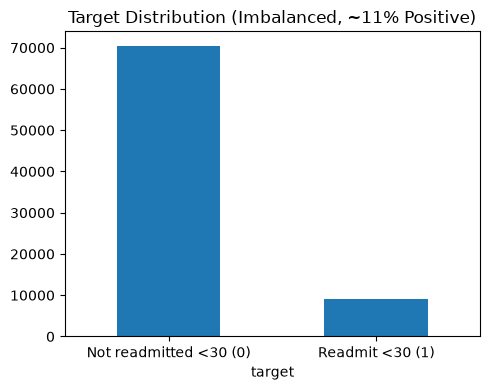

In [20]:
fig, ax = plt.subplots(figsize=(5, 4))
train_df['target'].value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_xticklabels(['Not readmitted <30 (0)', 'Readmit <30 (1)'], rotation=0)
ax.set_title('Target Distribution (Imbalanced, ~11% Positive)')
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/target_distribution.png", dpi=150)
plt.show()

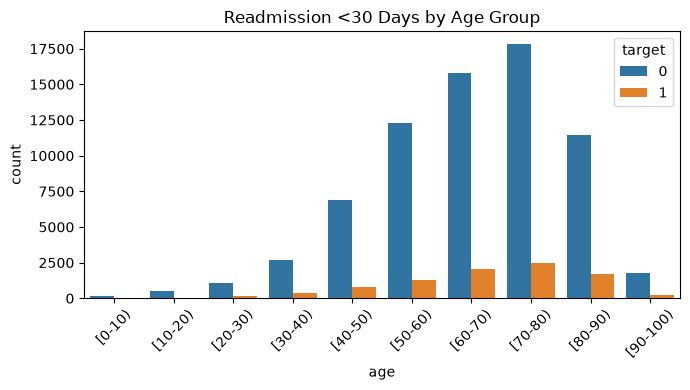

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=train_df, x='age', hue='target', ax=ax,
              order=sorted(train_df['age'].unique()))
ax.set_title('Readmission <30 Days by Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/age_vs_target.png", dpi=150)
plt.show()

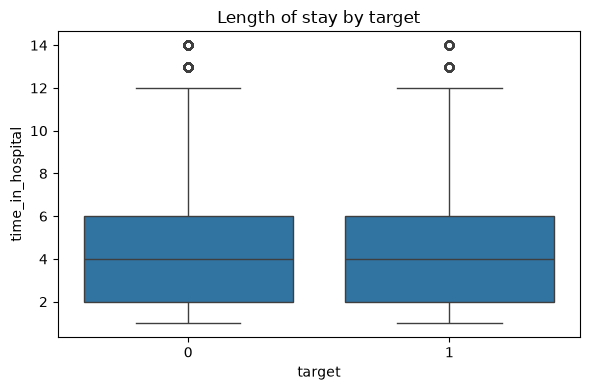

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=train_df, x='target', y='time_in_hospital', ax=ax)
ax.set_title('Length of stay by target')
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/time_in_hospital_vs_target.png", dpi=150)
plt.show()

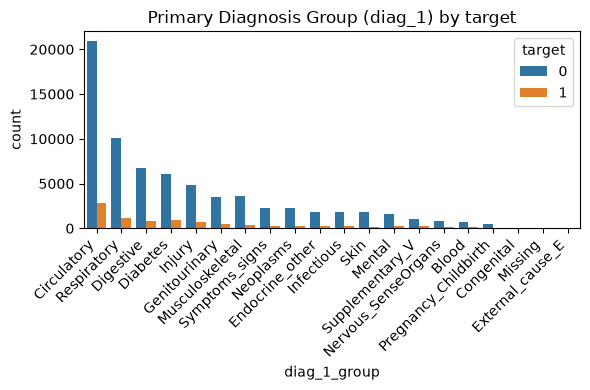

In [23]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=train_df, x='diag_1_group', hue='target', ax=ax,
              order=train_df['diag_1_group'].value_counts().loc[lambda s: s > 0].index)
ax.set_title('Primary Diagnosis Group (diag_1) by target')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/diag1_group_vs_target.png", dpi=150)
plt.show()

number_inpatient      0.166614
number_emergency      0.073098
number_diagnoses      0.053762
time_in_hospital      0.046483
num_medications       0.041445
number_outpatient     0.027191
num_lab_procedures    0.024962
num_procedures       -0.014765
Name: target, dtype: float64


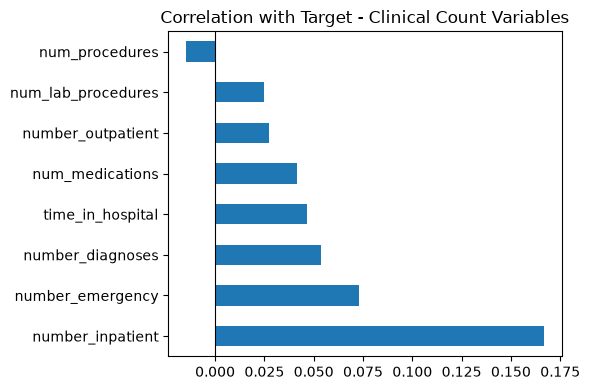

In [24]:
# --- Clinical count variables vs target ---
num_cols = [
    "number_inpatient", "number_emergency", "number_outpatient",
    "num_medications", "num_lab_procedures", "num_procedures",
    "time_in_hospital", "number_diagnoses",
]
corr_target = (
    train_df[num_cols + ["target"]].corr()["target"].drop("target")
    .sort_values(key=abs, ascending=False)
)
print(corr_target)

fig, ax = plt.subplots(figsize=(6, 4))
corr_target.plot(kind="barh", ax=ax)
ax.set_title("Correlation with Target - Clinical Count Variables")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/numeric_corr_with_target.png", dpi=150)
plt.show()

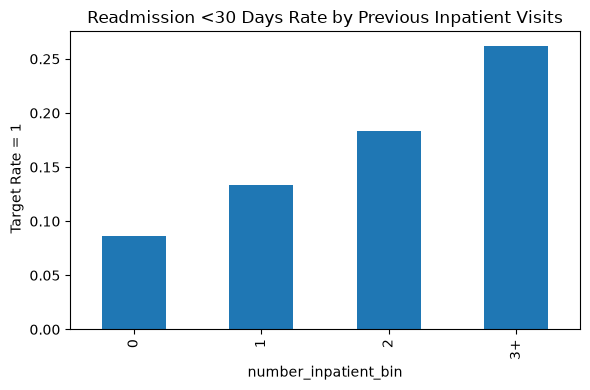

In [25]:
# --- Number_inpatient by bin (strongest feature) ---
fig, ax = plt.subplots(figsize=(6, 4))
bins = [0, 1, 2, 3, train_df["number_inpatient"].max() + 1]
labels = ["0", "1", "2", "3+"]
train_df["number_inpatient_bin"] = pd.cut(
    train_df["number_inpatient"], bins=bins, labels=labels,
    right=False, include_lowest=True
)
rate_by_bin = train_df.groupby("number_inpatient_bin", observed=True)["target"].mean()
rate_by_bin.plot(kind="bar", ax=ax)
ax.set_title("Readmission <30 Days Rate by Previous Inpatient Visits")
ax.set_ylabel(" Target Rate = 1")
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/number_inpatient_vs_target.png", dpi=150)
plt.show()
# Remove the temporary column after plotting; not save it to the file
train_df = train_df.drop(columns=["number_inpatient_bin"])

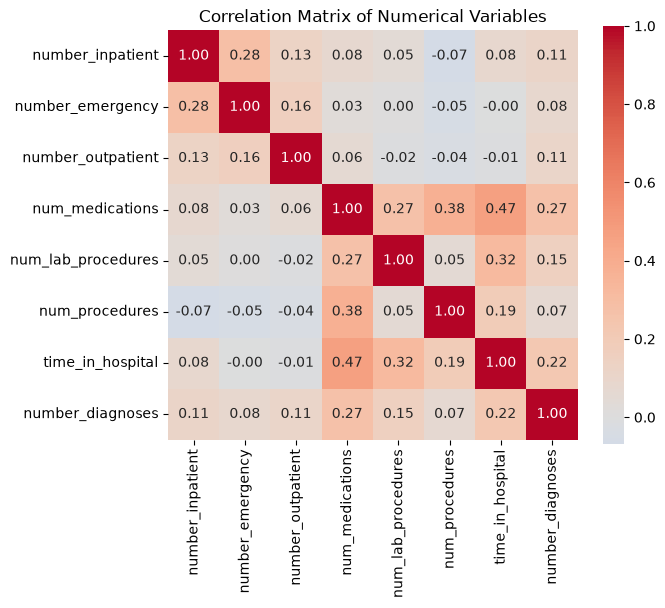

In [26]:
# --- Correlation matrix among numerical variables ---
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(train_df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=ax, square=True)
ax.set_title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/numeric_corr_heatmap.png", dpi=150)
plt.show()

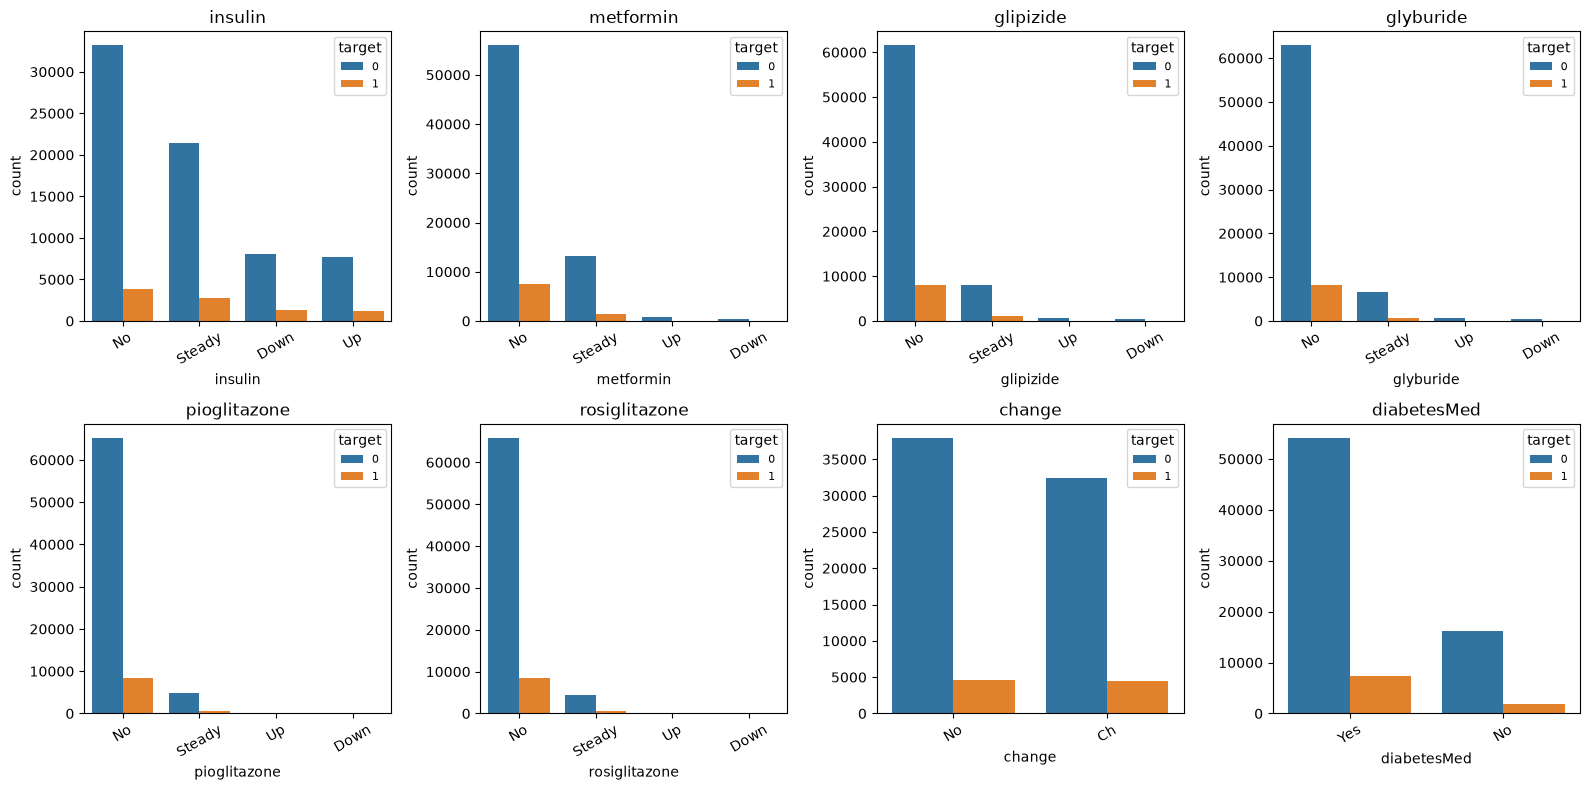

In [27]:
# --- Diabetes medications vs target ---
med_cols = ["insulin", "metformin", "glipizide", "glyburide",
            "pioglitazone", "rosiglitazone", "change", "diabetesMed"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), med_cols):
    order = train_df[col].value_counts().loc[lambda s: s > 0].index
    sns.countplot(data=train_df, x=col, hue="target", ax=ax, order=order)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="target", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/medication_cols_vs_target.png", dpi=150)
plt.show()

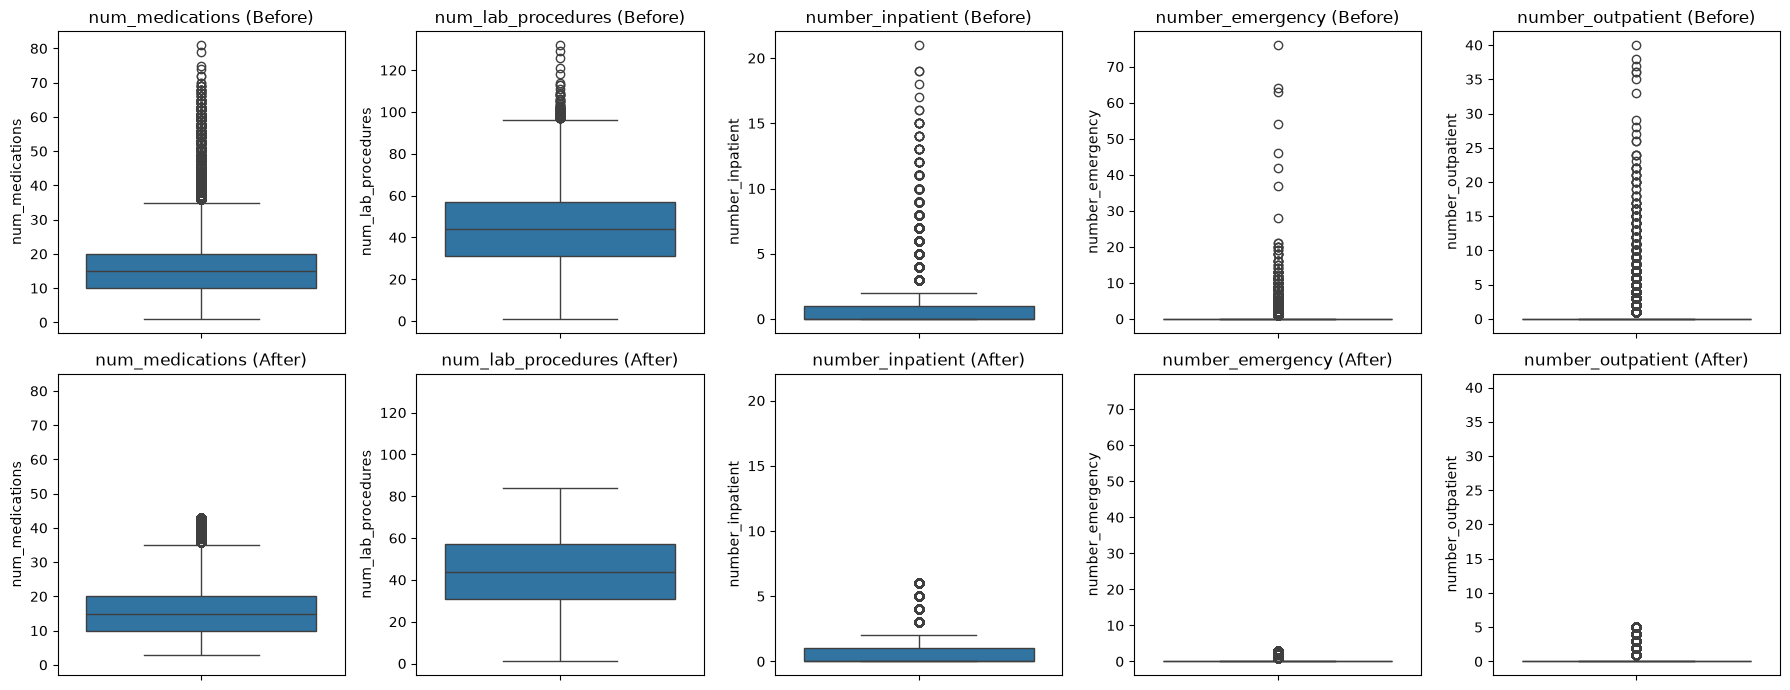

       num_medications  num_lab_procedures  number_inpatient  \
count     79541.000000        79541.000000      79541.000000   
mean         15.913554           42.863856          0.613721   
std           7.754861           19.430727          1.136423   
min           3.000000            1.000000          0.000000   
25%          10.000000           31.000000          0.000000   
50%          15.000000           44.000000          0.000000   
75%          20.000000           57.000000          1.000000   
max          43.000000           84.000000          6.000000   

       number_emergency  number_outpatient  
count      79541.000000       79541.000000  
mean           0.165437           0.331502  
std            0.526803           0.913749  
min            0.000000           0.000000  
25%            0.000000           0.000000  
50%            0.000000           0.000000  
75%            0.000000           0.000000  
max            3.000000           5.000000  


In [28]:
# --- Outliers / distributions of key numerical variables ---

# Compare distributions before and after winsorization
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey="col")

for j, col in enumerate(OUTLIER_COLS):
    sns.boxplot(data=before, y=col, ax=axes[0, j])
    axes[0, j].set_title(f"{col} (Before)")

    sns.boxplot(data=train_df, y=col, ax=axes[1, j])
    axes[1, j].set_title(f"{col} (After)")

plt.tight_layout()
plt.savefig(f"{OUTPUT_FIG_DIR}/outliers_before_after.png", dpi=150)
plt.show()

print(train_df[OUTLIER_COLS].describe())

In [29]:
# --- Association Between Categorical Variables and Target (Cramer's V) ---
from scipy.stats import chi2_contingency

def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return (chi2 / (n * (min(r, k) - 1))) ** 0.5

cat_cols_to_check = [
    "race", "gender", "age", "admission_type_id",
    "discharge_disposition_id", "admission_source_id",
    "diag_1_group", "diag_2_group", "diag_3_group",
    "insulin", "change", "diabetesMed", "A1Cresult", "max_glu_serum",
]

results = []
for col in cat_cols_to_check:
    if col in train_df.columns:
        ct = pd.crosstab(train_df[col], train_df["target"])
        v = cramers_v(ct)
        chi2, p, _, _ = chi2_contingency(ct)
        results.append({"column": col, "cramers_v": v, "p_value": p})

cat_assoc_df = pd.DataFrame(results).sort_values("cramers_v", ascending=False)
cat_assoc_df

,column,cramers_v,p_value
4,discharge_disposition_id,0.112332,8.657883e-201
8,diag_3_group,0.044049,3.180541e-23
9,insulin,0.043395,2.928568e-32
6,diag_1_group,0.040145,3.205707e-18
2,age,0.038690,2.074287e-21
7,diag_2_group,0.037305,5.943767e-15
5,admission_source_id,0.024804,9.192013e-06
11,diabetesMed,0.024642,3.662027e-12
12,A1Cresult,0.022112,1.832172e-08
3,admission_type_id,0.018464,5.411959e-05


## 7. Save Processed Files

In [30]:
# Drop raw ICD-9 diagnosis codes.
# Keep diag_1_group, diag_2_group, diag_3_group for modelling.
train_df = train_df.drop(columns=["diag_1", "diag_2", "diag_3"])
test_df = test_df.drop(columns=["diag_1", "diag_2", "diag_3"])

train_df.to_csv("../data/train_clean.csv", index=False)
test_df.to_csv("../data/test_clean.csv", index=False)

print("Saved data/train_clean.csv and data/test_clean.csv")

Saved data/train_clean.csv and data/test_clean.csv
